# Telepathy-like teaching: rebuild the main table, figure and live test

This notebook rebuilds, from the files in `data/` only (no GPU, about a minute):

1. **Table 1** of the paper: the online teachers on one GPU type (addendum 206).
2. **The cross-model against self-corrector analysis** (amendment 206c): paired on the gate's 240 held rows, with a bootstrap over repositories.
3. **Figure 2**: closeness to the teacher over the stream, and what each ingredient adds.
4. **The live test** (addenda 196, 202, 207, 208): solves per arm and by-task sign tests.

Teacher: Gemma 4 E4B. Student: Gemma 4 E2B with a rank-16 LoRA. Teachers of the LoRA: **C** E4B's own distribution; **D** the student corrected by a state corrector fed E4B's hidden states (telepathy-like); **S** the same corrector form fed the student's own states (the control); **D4 / S4** correctors fitted four times longer; **DI** a cross-model corrector penalised for writes the student's states cannot predict.

Training itself cannot be rerun from this repository (the inputs are private; see the README). Everything below reads the per-run result files that the training sessions wrote. Needs Python 3.9+, `numpy` and `matplotlib` (only for the figure).

In [1]:
from pathlib import Path
import json, subprocess, sys
ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent   # run from the repository root or from notebooks/
R = json.load(open(ROOT / "data/results.json"))["online g4"]
def run(*args):
    print(subprocess.run([sys.executable, *map(str, args)], capture_output=True, text=True, cwd=ROOT).stdout)
print("teachers:", ", ".join(f"{k} (seeds {', '.join(sorted(v))})" for k, v in R["table"].items()))
print("gate partition:", R["partition"])

teachers: C (seeds 1), S (seeds 1, 2), D (seeds 1, 2), DI (seeds 1, 2), S4 (seeds 1, 2), D4 (seeds 1, 2)
gate partition: {'differing': 52, 'agreeing': 168}


## 1. Table 1: the online teachers on one GPU type

*Held CE*: cross-entropy to E4B on held repositories at the end of the 600-item stream (untrained E2B: 0.825; lower is closer). *Prequential gain*: nats per token gained over the original E2B on each item before learning it (higher is faster). *Net*: of 220 held decisions, those fixed (of the 52 where E2B alone differs from E4B) minus those broken (of the other 168).

In [2]:
name = {"C": "C  E4B's distribution", "S": "S  self-corrector", "D": "D  cross-model corrector", "DI": "DI cross-model, imitable", "S4": "S4 self-corrector, 4x", "D4": "D4 cross-model, 4x"}
print(f"{'teacher':28s} {'seed':>4s} {'held CE':>8s} {'gain':>7s} {'fixed':>6s} {'broken':>7s} {'net':>5s} {'reaches C final at item':>24s}")
for k in ("C", "S", "D", "DI", "S4", "D4"):
    for sd, v in sorted(R["table"].get(k, {}).items()):
        print(f"{name[k]:28s} {sd:>4s} {v['held ce']:8.4f} {v['gain']:7.4f} {v['fixed']:6d} {v['broken']:7d} {v['net']:+5d} {str(v.get("item reaching C's final", '')):>24s}")

teacher                      seed  held CE    gain  fixed  broken   net  reaches C final at item
C  E4B's distribution           1   0.7669  0.0391     21       8   +13                         
S  self-corrector               1   0.7563  0.0628     13       3   +10                      100
S  self-corrector               2   0.7536  0.0596     21       6   +15                         
D  cross-model corrector        1   0.7536  0.0653     23       4   +19                      100
D  cross-model corrector        2   0.7520  0.0631     19       3   +16                         
DI cross-model, imitable        1   0.7538  0.0644     20       1   +19                      150
DI cross-model, imitable        2   0.7506  0.0610     22       2   +20                         
S4 self-corrector, 4x           1   0.7443  0.0699     22       5   +17                      100
S4 self-corrector, 4x           2   0.7449  0.0659     22       7   +15                         
D4 cross-model, 4x            

The same table straight from the per-run files, with the paired sign tests on the 220 decisions (`scripts/g4_table.py`):

In [3]:
run(ROOT / "scripts/g4_table.py")

s1 S   fixed 13 broken  3 net +10 | held CE 0.7563 drift 0.0141 qdrift 0.0386 | preq 0.0628 | gate CE 0.7619 | flips 3 | teacher control items 600
s1 D   fixed 23 broken  4 net +19 | held CE 0.7536 drift 0.0167 qdrift 0.0152 | preq 0.0653 | gate CE 0.7593 | flips 3 | teacher bridge items 600
s1 S4  fixed 22 broken  5 net +17 | held CE 0.7443 drift 0.0166 qdrift 0.0182 | preq 0.0699 | gate CE 0.753 | flips 3 | teacher control items 600
s1 D4  fixed 24 broken  4 net +20 | held CE 0.7409 drift 0.0143 qdrift 0.0364 | preq 0.0700 | gate CE 0.7519 | flips 3 | teacher bridge items 600
s1 DI  fixed 20 broken  1 net +19 | held CE 0.7538 drift 0.0150 qdrift 0.0227 | preq 0.0644 | gate CE 0.7601 | flips 3 | teacher bridge items 600
s1 C   fixed 21 broken  8 net +13 | held CE 0.7669 drift 0.0156 qdrift 0.0198 | preq 0.0391 | gate CE 0.7763 | flips 3 | teacher direct items 600
s2 S   fixed 21 broken  6 net +15 | held CE 0.7536 drift 0.0158 qdrift 0.0220 | preq 0.0596 | gate CE 0.7603 | flips 3 | te

## 2. What the teacher's states add: cross-model against self-corrector

Every student is scored on the same 240 held gate rows (118 episodes, 17 repositories). The differences below are first minus second, so negative means the first student is closer to E4B. Intervals are bootstraps over rows, episodes and repositories.

This analysis was added after two seeds; the pre-registered bar (0.005 lower in every seed) was not met. See `PREREGISTRATION.md`, addendum 206 and amendments 206c and 206d.

In [4]:
run(ROOT / "scripts/g4_rows.py")

closeness on the gate's 240 held rows: first minus second (negative: the first student is closer to E4B)
  seed 1 D vs S                  -0.0027 | rows [-0.0038, -0.0015] | episodes [-0.0037, -0.0015] | repos [-0.0038, -0.0017] | closer in 15 of 17 repos
  seed 1 D4 vs S4                -0.0011 | rows [-0.0025, +0.0003] | episodes [-0.0026, +0.0004] | repos [-0.0021, +0.0000] | closer in 13 of 17 repos
  seed 1 D vs C                  -0.0170 | rows [-0.0208, -0.0132] | episodes [-0.0208, -0.0132] | repos [-0.0202, -0.0131] | closer in 16 of 17 repos
  seed 1 S vs C                  -0.0144 | rows [-0.0184, -0.0102] | episodes [-0.0184, -0.0105] | repos [-0.0177, -0.0101] | closer in 16 of 17 repos
  seed 1 D4 vs D                 -0.0074 | rows [-0.0097, -0.0053] | episodes [-0.0092, -0.0056] | repos [-0.0091, -0.0059] | closer in 17 of 17 repos
  seed 1 S4 vs S                 -0.0090 | rows [-0.0108, -0.0073] | episodes [-0.0107, -0.0074] | repos [-0.0113, -0.0070] | closer in 16 o

In [5]:
P = R["pairs"]; K = "rows: mean, lo, hi, repos closer, repos"
cs = P["cross vs self"]
print(f"cross-model minus self-corrector, {cs['pairs']} pairs: {cs[K][0]:+.4f} nats [{cs[K][1]:+.4f}, {cs[K][2]:+.4f}], closer in {cs[K][3]} of {cs[K][4]} repositories")
print("pairs with the cross-model student closer:", cs["pairs with the cross student closer"], "of", cs["pairs"], "| pair means:", cs["pair means"])
print("per decision (more cross students match E4B, more self students match, p):", cs["decisions: more cross students match, more self students match, p"])
for k in ("D vs C", "S vs C", "D4 vs D", "S4 vs S", "DI vs D"):
    v = P[k]["all seeds"]; print(f"for scale, {k}: {v[K][0]:+.4f} [{v[K][1]:+.4f}, {v[K][2]:+.4f}] (seeds {v['seeds']})")

cross-model minus self-corrector, 4 pairs: -0.0019 nats [-0.0026, -0.0012], closer in 15 of 17 repositories
pairs with the cross-model student closer: 4 of 4 | pair means: [-0.0027, -0.001, -0.0011, -0.0028]
per decision (more cross students match E4B, more self students match, p): [19, 7, 0.029]
for scale, D vs C: -0.0170 [-0.0202, -0.0131] (seeds [1])
for scale, S vs C: -0.0144 [-0.0177, -0.0102] (seeds [1])
for scale, D4 vs D: -0.0081 [-0.0095, -0.0066] (seeds [1, 2])
for scale, S4 vs S: -0.0080 [-0.0095, -0.0065] (seeds [1, 2])
for scale, DI vs D: -0.0001 [-0.0012, +0.0009] (seeds [1, 2])


## 3. Figure 2

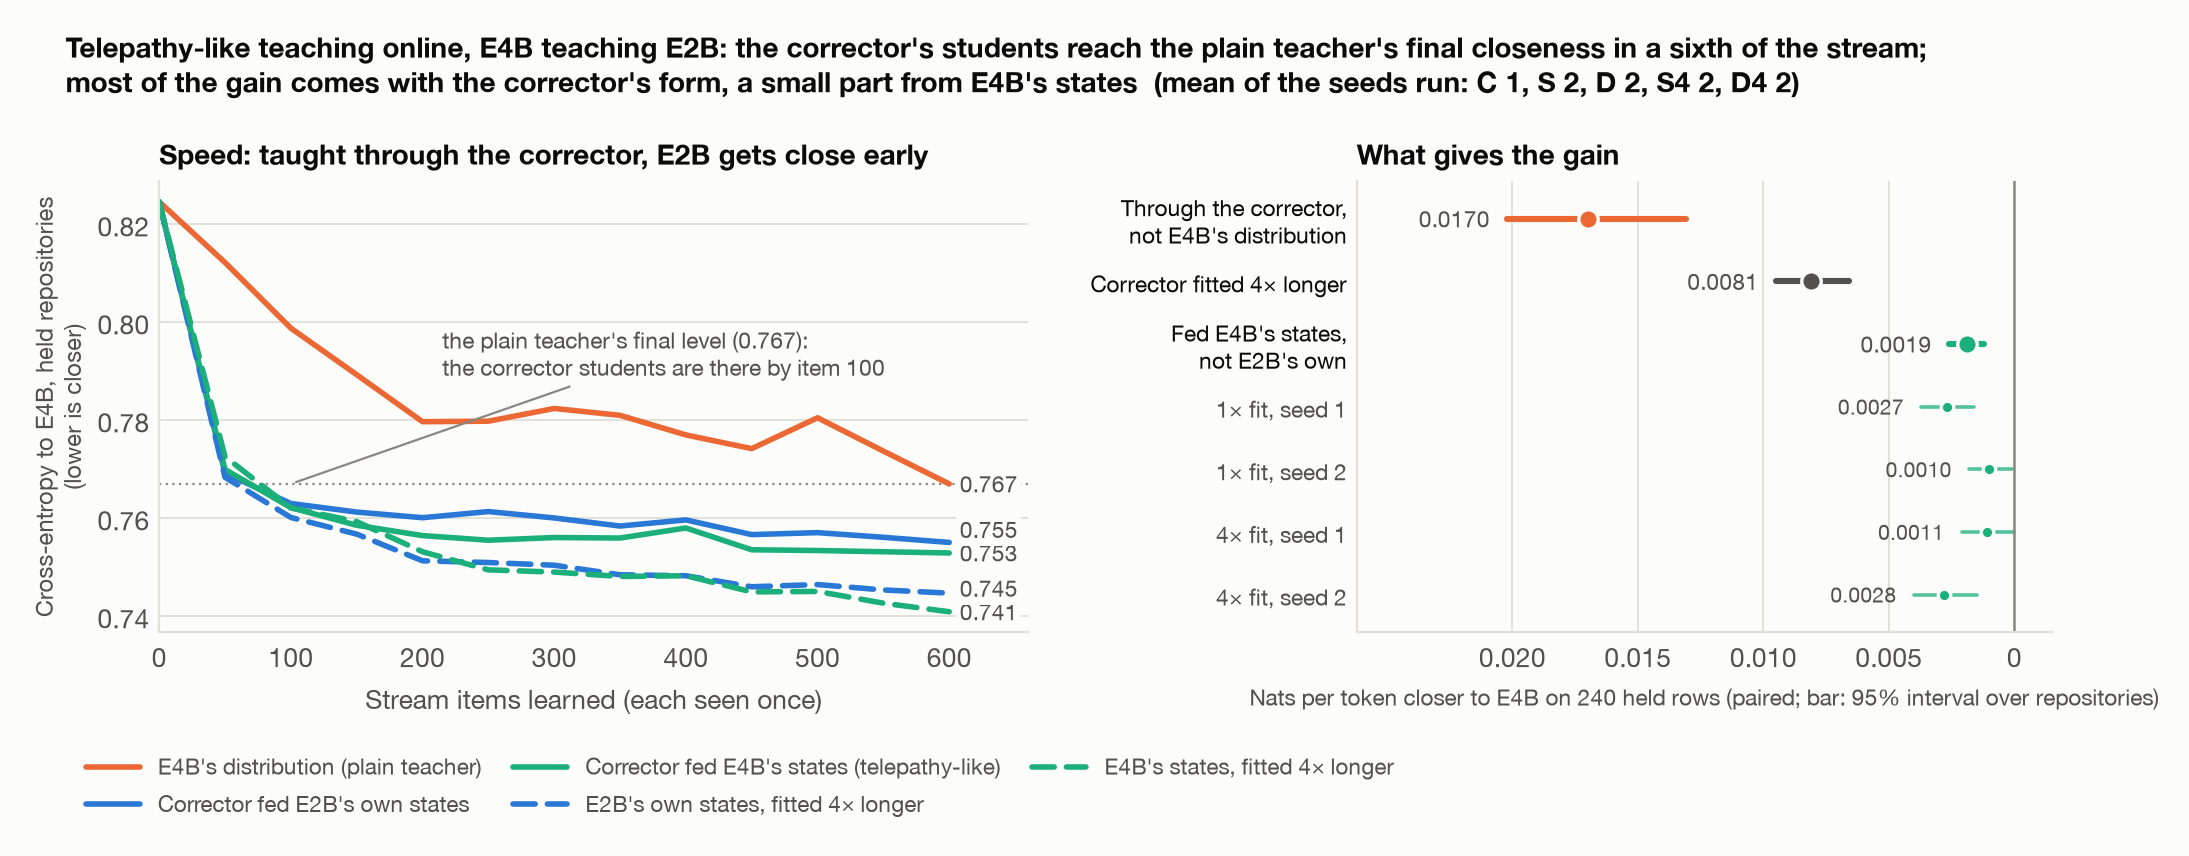

In [6]:
import tempfile
from IPython.display import Image, display
out = Path(tempfile.mkdtemp())
subprocess.run([sys.executable, str(ROOT / "scripts/figures.py"), str(ROOT / "data/results.json"), str(out), "fig_online"], check=True, capture_output=True)
display(Image(filename=str(out / "fig7_online.png"), width=1000))

## 4. The live test

Each attempt runs 80 held-out-repository agent tasks once in the competition's harness (E4B solved none of them). The *null adapter* is D's adapter with its output matrices set to zero: untrained E2B through the same serving path. Comparisons are by task on the solve rate, with exact two-sided sign tests, as pre-registered.

In [7]:
run(ROOT / "scripts/live_table.py")

arm                      attempts  solved      tasks  errors (time-outs)  calls/task  solved per attempt
C LoRA (4090 seed 1)            2    5 of 160      4      25 ( 20)          22.2      3, 2
D LoRA (4090 seed 1)            4   19 of 320     12      73 ( 48)          21.1      5, 6, 3, 5
D4 LoRA (A100 seed 1)           2   13 of 160      9      17 ( 11)          15.9      5, 8
null adapter                    2    2 of 160      2       9 (  4)          14.6      2, 0
plain E2B                       4    7 of 320      5      19 (  1)          14.0      4, 1, 1, 1

by task: higher solve rate on / lower on (exact sign test)
  D LoRA (4090 seed 1) vs null adapter: 12 vs 0, p = 0.0005
  D LoRA (4090 seed 1) vs plain E2B: 9 vs 1, p = 0.0215
  D LoRA (4090 seed 1) vs C LoRA (4090 seed 1): 9 vs 3, p = 0.1460
  D4 LoRA (A100 seed 1) vs null adapter: 8 vs 1, p = 0.0391
  D4 LoRA (A100 seed 1) vs D LoRA (4090 seed 1): 6 vs 5, p = 1.0000
  C LoRA (4090 seed 1) vs null adapter: 3 vs 1, p = 0.625

## Where to look next

- `paper.md`: the paper. `SCORECARD.md`: which pre-registered predictions held.
- `PREREGISTRATION.md`: designs, predictions and results as they were written, addenda 165 onwards.
- `data/online/`: one result file per run (`g4_*` are the one-GPU table; `a100_*` and unprefixed files are the earlier runs on other GPU types).
- `code/transfer/online.py`: the online test; `code/colab/xq_online.sh`: one session.